In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from transformers import pipeline, GPT2LMHeadModel, GPT2Tokenizer
import torch
import gzip, json, random, time
import seaborn as sns
from tabulate import tabulate

In [2]:
ai_models = {}

def setup_ai_models():
    """Setup available AI models"""
    global ai_models
    print("Loading AI models for demonstration...")

    ai_models['text_generator'] = pipeline(
        "text-generation",
        model="gpt2"
    )

    ai_models['sentiment'] = pipeline(
        "sentiment-analysis",
        model="distilbert-base-uncased-finetuned-sst-2-english"
    )

    ai_models['classifier'] = pipeline(
        "zero-shot-classification",
        model="facebook/bart-large-mnli"
    )

    print("✅ Models loaded successfully!")
    return ai_models

ai_models = setup_ai_models()

Loading AI models for demonstration...


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✅ Models loaded successfully!


In [3]:
def demonstrate_text_generation():
    """Show how AI generates text"""
    print("\nTEXT GENERATION DEMO")
    print("-" * 50)

    prompts = [
        "The future of artificial intelligence",
        "Best practices for online shopping",
        "Benefits of using AI in business"
    ]

    if 'text_generator' in ai_models:
        for prompt in prompts:
            try:
                result = ai_models['text_generator'](
                    prompt,
                    max_length=60,
                    num_return_sequences=1,
                    temperature=0.7
                )
                generated = result[0]['generated_text']
                print(f"Prompt: {prompt}")
                print("AI Response:")
                print(generated)
                print("-" * 50)
            except Exception as e:
                print(f"Error with prompt: {prompt}")
                print(f"Details: {e}")
                print("-" * 50)

demonstrate_text_generation()

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.



TEXT GENERATION DEMO
--------------------------------------------------


[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Prompt: The future of artificial intelligence
AI Response:
The future of artificial intelligence is uncertain. It may be that the future of artificial intelligence will be more complicated than we know. But it's been a long time since we had artificial intelligence, and the future might be more complicated than we think.

The past few years have seen both advances and futurists call for a "re-thinking" of the way we think about artificial intelligence. Some are talking about replacing human intelligence with machines. For example, one prominent futurist told me that the problem of artificial intelligence is a "moral" problem, and that it is essential to "move toward an ethical, scientific, moral, and social world."

Some are making the case that artificial intelligence will eventually become more like human intelligence. They include:

Machine learning. This is the idea that, for example, we can learn about our own bodies, understand how our faces work, and learn about our emotions.

M

[transformers] Both `max_new_tokens` (=256) and `max_length`(=60) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Prompt: Best practices for online shopping
AI Response:
Best practices for online shopping:

If you are interested in purchasing a new PC, you will need to consider a number of free online retailers. Some of these are available under the "Buy Now" and "Sell Now" sections of the website.

At Amazon.com, you can buy or sell your own branded PC (Amazon.ca and Amazon.co.uk) from a wide range of online retailers. It is not as straightforward as you might think.

Find a local retailer that you like and then try to find an online retailer that will have a PC PC that you like.

If you are interested in buying your own PC from a local retailer, check out our list of the top online retailers.

Get an estimate for your PC PC

If you are looking for a PC that I have personally found to be a great one, then you should look no further.

If you are not sure which online retailer to go for, you can search by country and by market. It's the same for the prices of PCs we have listed.

It is important to

In [4]:
def demonstrate_content_and_classification():
    """Demo for sentiment analysis and text classification"""
    # --- Sentiment Analysis ---
    reviews = [
        "This product is amazing! Best purchase ever!",
        "Terrible quality, waste of money.",
        "It's okay, nothing special but does the job."
    ]

    if 'sentiment' in ai_models:
        print("\nSentiment Analysis")
        for review in reviews:
            result = ai_models['sentiment'](review)[0]
            print(f"Review: {review}")
            print(f"Sentiment: {result['label']} | Confidence Score: {result['score']:.2f}\n")

    # --- Text Classification ---
    texts = [
        "AI is transforming healthcare by improving diagnosis accuracy.",
        "The football team won their championship game yesterday.",
        "Investors are excited about the growth of renewable energy."
    ]
    labels = ["Technology", "Sports", "Business", "Health"]

    if 'classifier' in ai_models:
        print("\nText Classification")
        for text in texts:
            result = ai_models['classifier'](text, candidate_labels=labels)
            print(f"Text: {text}")
            print(f"Category: {result['labels'][0]} | Confidence Score: {result['scores'][0]:.2f}\n")

demonstrate_content_and_classification()


Sentiment Analysis
Review: This product is amazing! Best purchase ever!
Sentiment: POSITIVE | Confidence Score: 1.00

Review: Terrible quality, waste of money.
Sentiment: NEGATIVE | Confidence Score: 1.00

Review: It's okay, nothing special but does the job.
Sentiment: POSITIVE | Confidence Score: 1.00


Text Classification
Text: AI is transforming healthcare by improving diagnosis accuracy.
Category: Technology | Confidence Score: 0.64

Text: The football team won their championship game yesterday.
Category: Sports | Confidence Score: 0.99

Text: Investors are excited about the growth of renewable energy.
Category: Business | Confidence Score: 0.49



In [5]:
results = {}

def ai_collaboration():
    """Generator + Sentiment + Classifier working together"""
    product = "SmartWatch Pro"

    # Step 1: Generate description
    desc = ai_models['text_generator'](
        f"{product} features",
        max_new_tokens=20,
        temperature=0.7
    )[0]['generated_text']

    desc = desc.replace(f"{product} features", "").strip()
    full_text = f"{product} features {desc}"

    # Step 2: Sentiment analysis
    mood = ai_models['sentiment'](full_text)[0]
    sentiment = f"{mood['label']} ({mood['score']:.2f})"

    # Step 3: Classification
    categories = ["Electronics", "Sports", "Fashion"]
    cat = ai_models['classifier'](full_text, candidate_labels=categories)
    classification = f"{cat['labels'][0]} ({cat['scores'][0]:.2f})"

    # Save results
    results['ai_version'] = {
        "text": full_text,
        "sentiment": sentiment,
        "category": classification
    }

    print("Generated:", full_text)
    print("Sentiment:", sentiment)
    print("Category:", classification)

ai_collaboration()

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=20) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Generated: SmartWatch Pro features a built-in microphone that lets you control the Watch with the buttons on the back of your wrist
Sentiment: NEGATIVE (0.82)
Category: Electronics (0.69)


In [6]:
def step2_human_feedback():
    """Collect human feedback on missing features"""
    original = results.get('ai_version', {}).get('text', 'SmartWatch Pro features basic functions')
    print("Original:", original)
    feedback = input("What features should be added? (e.g., battery life, waterproof): ")
    results['human_feedback'] = feedback.strip()
    return feedback


def step3_direct_ai_improvement():
    """GPT-2 rewrites the description using human feedback"""
    original = results.get('ai_version', {}).get('text', '').strip()
    feedback = results.get('human_feedback', '').strip()

    prompt = (
        f"Original: {original}\n"
        f"Rewrite the product description to include {feedback}.\n"
    )

    output = ai_models['text_generator'](
        prompt,
        max_new_tokens=120,
        temperature=0.7,
        top_p=0.9,
        pad_token_id=50256,
        return_full_text=False
    )[0]['generated_text']

    results['final_improved'] = output
    print("Improved:", output)


step2_human_feedback()
step3_direct_ai_improvement()

Original: SmartWatch Pro features a built-in microphone that lets you control the Watch with the buttons on the back of your wrist


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'top_p', 'temperature', 'pad_token_id'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=120) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Improved: The smartwatch comes with a built-in microphone that lets you control the Watch with the buttons on the back of your wrist.
The watch comes with a built-in microphone that lets you control the Watch with the buttons on the back of your wrist.
The watch comes with a built-in microphone that lets you control the Watch with the buttons on the back of your wrist.
The watch comes with a built-in microphone that lets you control the Watch with the buttons on the back of your wrist.
The watch comes with a built-in microphone that lets you control the Watch


In [7]:
def parse(path):
    """Parse a .jsonl.gz file line by line"""
    with gzip.open(path, 'rb') as f:
        for line in f:
            yield json.loads(line)


def load_amazon_data(review_path, meta_path, max_records=5000):
    """Load Amazon review & metadata from .jsonl.gz files"""
    print("\nLOADING AMAZON DATASET")
    print("=" * 50)

    print("Reading reviews...")
    reviews = []
    for i, record in enumerate(parse(review_path)):
        reviews.append(record)
        if i + 1 >= max_records:
            break
    reviews_df = pd.DataFrame(reviews)

    print("Reading metadata...")
    metadata = []
    for i, record in enumerate(parse(meta_path)):
        metadata.append(record)
        if i + 1 >= max_records:
            break
    metadata_df = pd.DataFrame(metadata)

    print("Data Loaded Successfully!")
    return reviews_df, metadata_df


reviews_df, metadata_df = load_amazon_data(
    "./All_Beauty.jsonl.gz",
    "./meta_All_Beauty.jsonl.gz",
    max_records=5000
)


LOADING AMAZON DATASET
Reading reviews...
Reading metadata...
Data Loaded Successfully!



EXPLORING AMAZON DATA STRUCTURE

Dataset Sizes
+-----------+--------+-----------+
| Dataset   |   Rows |   Columns |
+===========+========+===========+
| Reviews   |   5000 |        10 |
+-----------+--------+-----------+
| Metadata  |   5000 |        14 |
+-----------+--------+-----------+

Reviews Columns
+-------------------+
| Column            |
+===================+
| rating            |
+-------------------+
| title             |
+-------------------+
| text              |
+-------------------+
| images            |
+-------------------+
| asin              |
+-------------------+
| parent_asin       |
+-------------------+
| user_id           |
+-------------------+
| timestamp         |
+-------------------+
| helpful_vote      |
+-------------------+
| verified_purchase |
+-------------------+

Metadata Columns
+-----------------+
| Column          |
+=================+
| main_category   |
+-----------------+
| title           |
+-----------------+
| average_rating  |
+-----

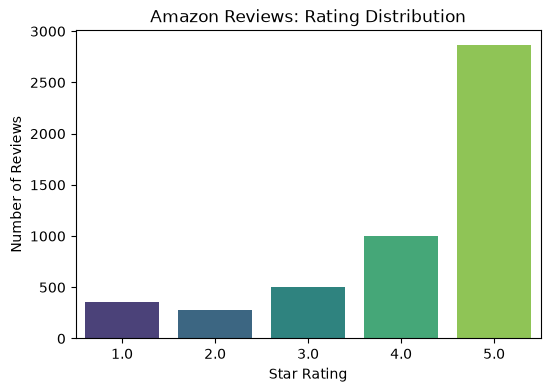

In [8]:
def explore_amazon_data_structure(reviews_df, metadata_df):
    """Explore and display data structure with formatted tables"""
    print("\nEXPLORING AMAZON DATA STRUCTURE")
    print("=" * 50)

    print("\nDataset Sizes")
    table = [
        ["Reviews", reviews_df.shape[0], reviews_df.shape[1]],
        ["Metadata", metadata_df.shape[0], metadata_df.shape[1]]
    ]
    print(tabulate(table, headers=["Dataset", "Rows", "Columns"], tablefmt="grid"))

    print("\nReviews Columns")
    print(tabulate([[c] for c in reviews_df.columns], headers=["Column"], tablefmt="grid"))

    print("\nMetadata Columns")
    print(tabulate([[c] for c in metadata_df.columns], headers=["Column"], tablefmt="grid"))

    print("\nSample Review")
    review_sample = reviews_df.iloc[0].to_dict()
    print(tabulate(review_sample.items(), headers=["Field", "Value"], tablefmt="grid"))

    print("\nSample Product Metadata")
    meta_sample = metadata_df.iloc[0].to_dict()
    print(tabulate(meta_sample.items(), headers=["Field", "Value"], tablefmt="grid"))

    if "rating" in reviews_df.columns:
        print("\nRating Distribution")
        rating_counts = reviews_df['rating'].value_counts().sort_index()
        print(tabulate(rating_counts.reset_index().values,
                       headers=["Rating", "Count"], tablefmt="grid"))

        plt.figure(figsize=(6, 4))
        sns.countplot(x="rating", data=reviews_df, palette="viridis",
                      order=sorted(reviews_df["rating"].dropna().unique()))
        plt.title("Amazon Reviews: Rating Distribution")
        plt.xlabel("Star Rating")
        plt.ylabel("Number of Reviews")
        plt.show()

explore_amazon_data_structure(reviews_df, metadata_df)


AI-POWERED AMAZON REVIEW DEMO

Review #1 (Product ID: B07ZJX5MNJ)
I have a set of Kolinsky sable brushes which moths got at a while ago and I have been wanting to replace them.  This was a perfect shape for me, so I got it.  Let's see what happened.<br /><br />WHAT IS THIS LIKE?<br />This has a wood handle for nails or even watercolor painting- it is a nice solid ...
Rating: 5.0
Sentiment: POSITIVE (confidence: 1.00)


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'pad_token_id', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=50) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Key Topic: Quality (confidence: 0.65)
AI Summary: This should be a nice brush for your face and all it is about is this.....
What does it do?<br />I recommend this brush because it is very versatile and it is the size of any brush. You can make your own

Review #2 (Product ID: B004GHIEZQ)
Love the feel on my skin.  Product arrived in tact--all good....
Rating: 5.0
Sentiment: POSITIVE (confidence: 1.00)


[transformers] Both `max_new_tokens` (=50) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Key Topic: Quality (confidence: 0.80)
AI Summary: The first product I reviewed at Good Smile Company, I'd say, was the "Love the feel on my skin" product. I had read the description of the product and thought I had heard about it online before, but I can confirm that

Review #3 (Product ID: B010HW5HV2)
they work for my daughter !...
Rating: 4.0
Sentiment: POSITIVE (confidence: 1.00)


...

Key Topic: Quality (confidence: 0.42)
AI Summary: This review is a compilation of all the reviews I've read about this product for the past 10 years. The reviews in the first paragraph are not particularly helpful, but the two paragraphs are helpful in explaining the difference between the two products. I don't

Review #4 (Product ID: B07YJR8R18)
Pro:<br />My cat adores this thing. He bugs me to brush him with it every night. He tries to climb onto my nightstand to remind me.<br /><br />Con: it doesn’t hold a candle to the amount of hair I get off him using my Hartz Groomer's Best Small Slicker Brush. The hair’s also much harder to get out o...
Rating: 5.0
Sentiment: NEGATIVE (confidence: 0.99)


[transformers] Both `max_new_tokens` (=50) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Key Topic: Quality (confidence: 0.59)
AI Summary: Pro:<br />I love this thing. I've never tried a headscratcher before, but this thing looks amazing.<br /><br />Con: it does hold a candle to the amount of hair I get off him using

Review #5 (Product ID: B08BXPZRQG)
Oh my GAWWWD! This thing is amazing! This will be a lengthy review, but if you are like me, I hope you'll enjoy the very detailed essay I am about to write for the 2nd time because my original review closed out of the page :(<br /><br />I will preface this by letting you know I have coarse, curly ha...
Rating: 5.0
Sentiment: POSITIVE (confidence: 0.97)


[transformers] Both `max_new_tokens` (=50) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Key Topic: Quality (confidence: 0.53)
AI Summary: I have watched a lot of Youtube videos and it is quite the experience. The videos are very nice and this is a great feeling, to see things in a way that is like a movie.
What I found is very interesting. The characters

VISUAL INSIGHTS


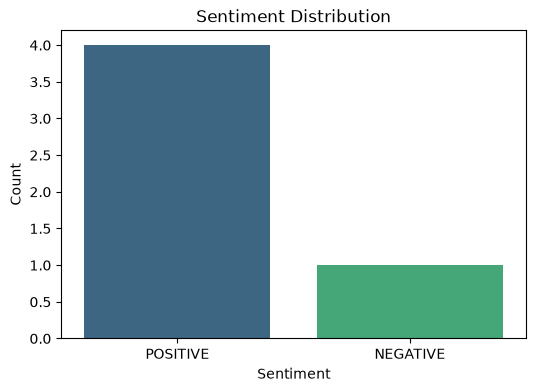

In [9]:
def ai_amazon_demo(reviews_df, metadata_df, num_reviews=5):
    print("\nAI-POWERED AMAZON REVIEW DEMO")
    print("=" * 55)

    candidate_labels = ["Quality", "Delivery", "Price", "Usability", "Durability"]
    sample_reviews = reviews_df.dropna(subset=['text']).sample(num_reviews)
    sentiments, categories = [], []

    for i, (_, review) in enumerate(sample_reviews.iterrows(), 1):
        text = str(review['text'])[:300]
        asin = review.get('asin', 'Unknown')
        rating = review.get('rating', 0)

        print(f"\nReview #{i} (Product ID: {asin})")
        print(f"{text}...")

        # ---- Sentiment Analysis ----
        if 'sentiment' in ai_models:
            result = ai_models['sentiment'](text)[0]
            sentiment = result['label']
            score = result['score']
        else:
            sentiment, score = ("POSITIVE" if rating >= 4 else "NEGATIVE", 0.9)
        sentiments.append(sentiment)
        print(f"Rating: {rating}")
        print(f"Sentiment: {sentiment} (confidence: {score:.2f})")

        # ---- Classification ----
        if 'classifier' in ai_models:
            classify = ai_models['classifier'](text, candidate_labels=candidate_labels)
            top_label = classify['labels'][0]
            cat_score = classify['scores'][0]
        else:
            top_label, cat_score = random.choice(candidate_labels), 0.8
        categories.append(top_label)
        print(f"Key Topic: {top_label} (confidence: {cat_score:.2f})")

        # ---- Text Generation (summary) ----
        if 'text_generator' in ai_models:
            prompt = f"Summarize this review in one sentence:\n{text}\nSummary:"
            generated = ai_models['text_generator'](
                prompt, max_new_tokens=50, temperature=0.7, pad_token_id=50256
            )[0]['generated_text']
            summary = generated.replace(prompt, "").strip()
        else:
            summary = f"This review mainly talks about {top_label.lower()}."
        print(f"AI Summary: {summary}")

        time.sleep(0.5)

    print("\nVISUAL INSIGHTS")
    plt.figure(figsize=(6, 4))
    sns.countplot(x=sentiments, palette="viridis")
    plt.title("Sentiment Distribution")
    plt.xlabel("Sentiment")
    plt.ylabel("Count")
    plt.show()

ai_amazon_demo(reviews_df, metadata_df)